# Cifar-10 FCN model

In [17]:
## Anni model asti

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras import layers
from keras import backend as K

import time

import numpy as np
import matplotlib.pyplot as plt

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

In [3]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)
print(y_train[:10])

(50000, 32, 32, 3)
(50000, 1)
(10000, 32, 32, 3)
(10000, 1)
[[6]
 [9]
 [9]
 [4]
 [1]
 [1]
 [2]
 [7]
 [8]
 [3]]


In [4]:
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

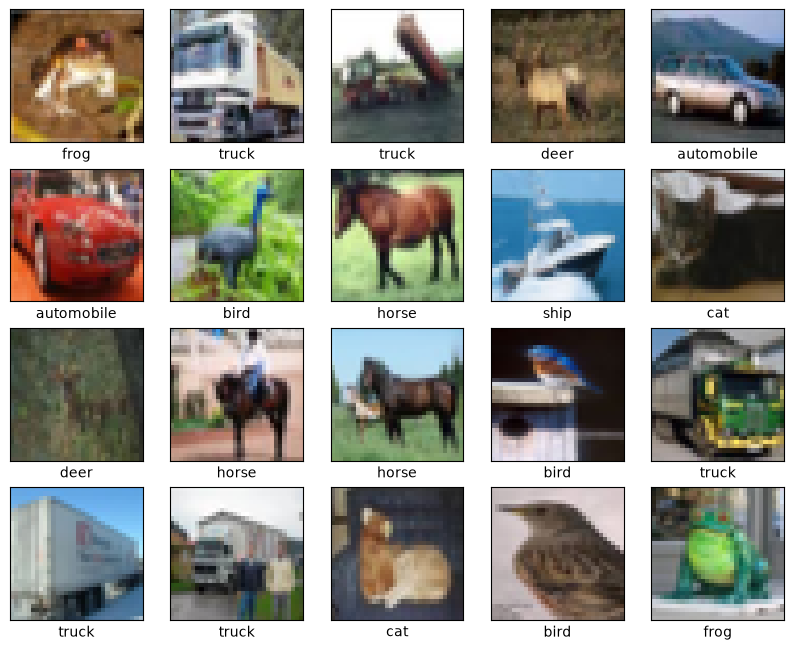

In [5]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(20):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    # The CIFAR labels happen to be arrays, 
    # which is why need the extra index
    plt.xlabel(class_names[y_train[i][0]])
plt.show()

In [6]:
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.RandomFlip("horizontal"),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,740,938 (6.64 MB)

 Trainable params: 1,739,914 (6.64 MB)

 Non-trainable params: 1,024 (4.00 KB)

In [ ]:
## ## Nur
## Suorituskykyä (tarkkuus testidatalla)
## Oppimiskäyrää (training vs. validation loss)

In [7]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [8]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

t0 = time.time()

history = model.fit(x_train, y_train, epochs=50, batch_size=64,
                    validation_split=0.1, callbacks=[callback], verbose=2)

train_time = time.time() - t0
print(f"Opetusaika: {train_time:.1f} s")

Epoch 1/50
704/704 - 5s - 7ms/step - accuracy: 0.3683 - loss: 1.7777 - val_accuracy: 0.3466 - val_loss: 1.8460
Epoch 2/50
704/704 - 4s - 5ms/step - accuracy: 0.4184 - loss: 1.6327 - val_accuracy: 0.3998 - val_loss: 1.6687
Epoch 3/50
704/704 - 4s - 6ms/step - accuracy: 0.4318 - loss: 1.5870 - val_accuracy: 0.3688 - val_loss: 1.7869
Epoch 4/50
704/704 - 4s - 6ms/step - accuracy: 0.4362 - loss: 1.5710 - val_accuracy: 0.3840 - val_loss: 1.7076
Epoch 5/50
704/704 - 4s - 6ms/step - accuracy: 0.4469 - loss: 1.5448 - val_accuracy: 0.4604 - val_loss: 1.5237
Epoch 6/50
704/704 - 4s - 5ms/step - accuracy: 0.4516 - loss: 1.5325 - val_accuracy: 0.4546 - val_loss: 1.5550
Epoch 7/50
704/704 - 4s - 5ms/step - accuracy: 0.4601 - loss: 1.5061 - val_accuracy: 0.4360 - val_loss: 1.5669
Epoch 8/50
704/704 - 4s - 6ms/step - accuracy: 0.4674 - loss: 1.4902 - val_accuracy: 0.4622 - val_loss: 1.5293
Epoch 9/50
704/704 - 4s - 6ms/step - accuracy: 0.4708 - loss: 1.4767 - val_accuracy: 0.4830 - val_loss: 1.4686
E

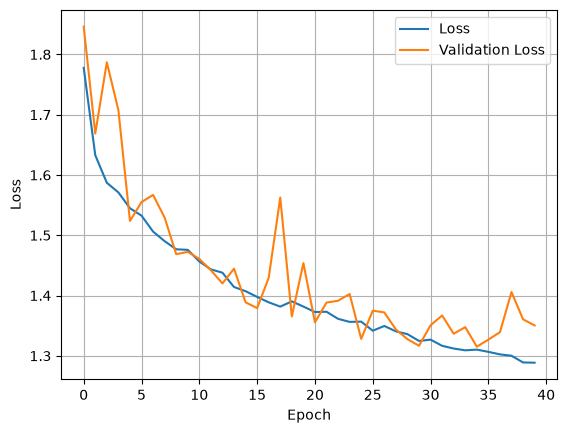

In [9]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

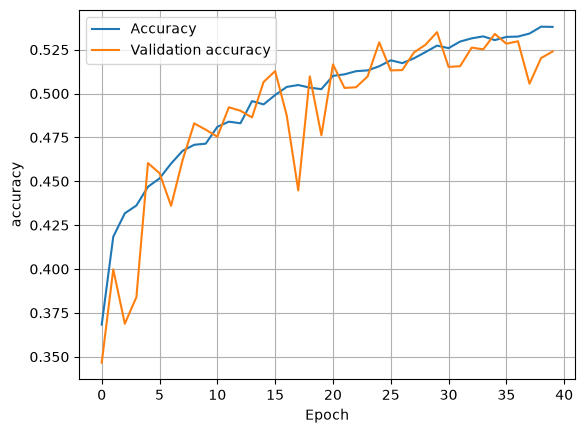

In [16]:
plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.grid()
plt.show()

In [10]:
test_scores = model.evaluate(x_test, y_test, verbose=2)
print("Test loss:", test_scores[0])
print("Test accuracy:", test_scores[1])

313/313 - 0s - 1ms/step - accuracy: 0.5345 - loss: 1.3152
Test loss: 1.3151739835739136
Test accuracy: 0.534500002861023


In [ ]:
## Sandra 
#Visualisoi tuloksia:

#Näytä esimerkkikuvia ja mallien luokittelutuloksia
#Esitä luokkien todennäköisyysjakaumia
#Analysoi väärin luokiteltuja kuvia

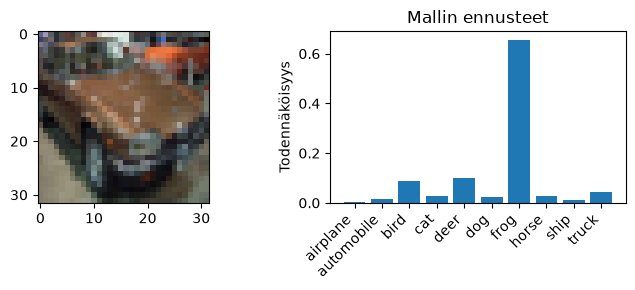

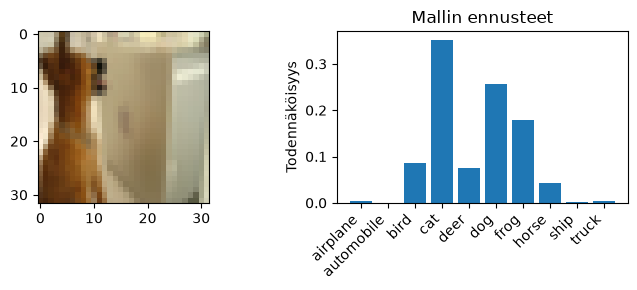

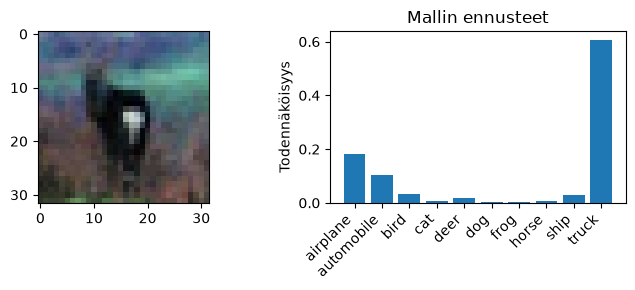

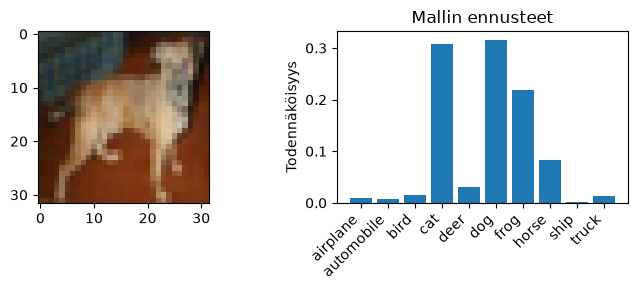

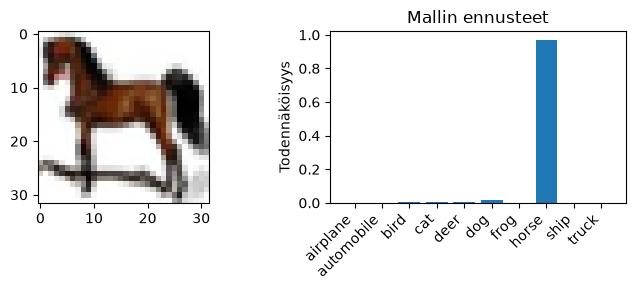

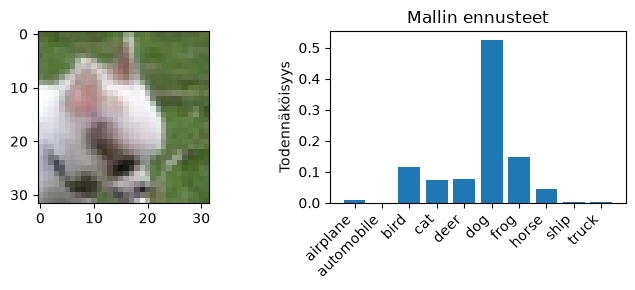

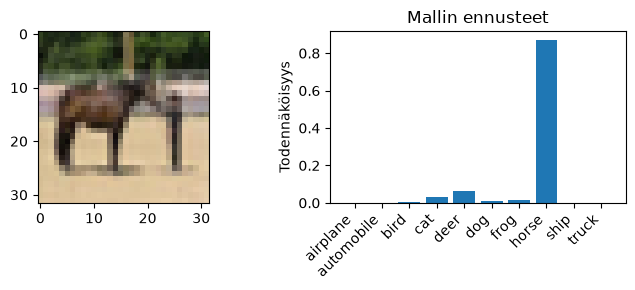

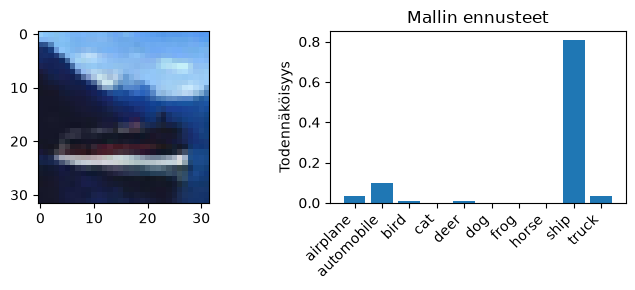

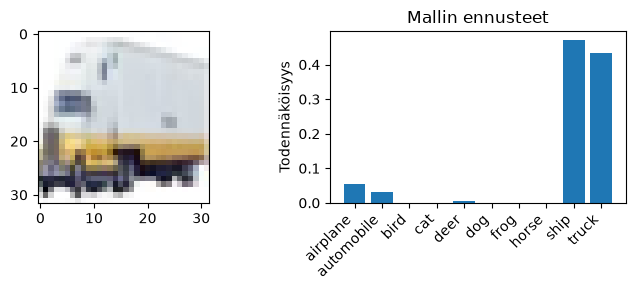

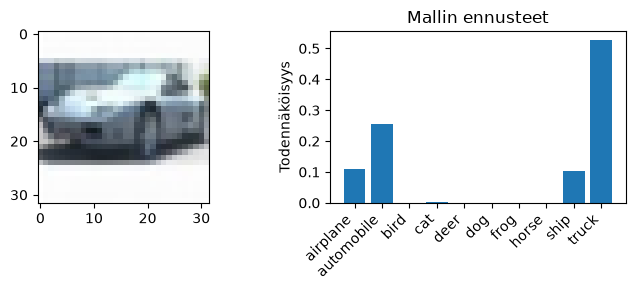

In [11]:
x = x_test
y = model(x)
start = 2000

for k in range(10):
    plt.figure(figsize=(7, 3))
    
    plt.subplot(1,2,1)
    plt.imshow(x[start+k])

    
    plt.subplot(1,2,2)
    plt.bar(class_names, y[start+k].numpy().flatten())
    plt.xticks(rotation=45, ha="right")
    
    plt.ylabel("Todennäköisyys")
    plt.title("Mallin ennusteet")
    plt.tight_layout()
    plt.show()

## Test results and conclusions (Riikka)

In order to improve the performance of the model, multiple different versions were tested. The goal was to increase the accuracy score while decreasing the test loss score. The training and validation accuracy and loss scores as well as the training time were also analyzed for the different versions. The tests were performed on one device the results might change if the tests are performed again. Different devices might require a lot more time to train the models. For example, while the final version of the model took around three minutes to train on one device, on another device it tooka around 15 minutes.

The table below shows the different versions that were tested, their accuracy and test loss scores, training time and conclusion about the tested version.

| Test            | Modification                                                                | Accuracy (%) | Test loss |  Training time (s) | Conclusion            |
| --------------- | --------------------------------------------------------------------------- | ------------ | --------- | ------------------ | --------------------- |
| Original model  |                                                                             | 49.97        | 1.408     | 69.2               |The accuracy of the model is not great. Training loss did decrease evenly but the validation loss did not decrease as much. The curves did not curve downwards at an even pace. The model cannot correctly predict most of the time.                |
| Version 1       | Added layer Dropout(0.3)                                                    | 46.50        | 1.530     | 132.7              |The accuracy and test loss scores are slightly worse and the training time increased noticeably, but the training loss and validation loss curves are now more even and the validation loss curve did decrease more.                |
| Version 2       | Added BatchNormalization()                                                  | 50.40        | 1.392     | 93.4               |The accuracy and test loss scores are better than before and training time decreased from the previous version.  Training loss and validation loss curves decreased evenly and the validation curve and values also seemed to become more stable in later epochs after having fluctuated a lot in the begining.                |
| Version 3       | Added Dense(128)                                                            | 50.90        | 1.380     | 64.8               |There is not much of a difference in the accuracy and loss scores but training time did decrease compared to the previous version.                |
| Version 4       | Changed the Dense(128) to Dense(64)                                         | 48.60        | 1.438     | 50.9               |The training time was faster but test accuracy and test loss scores are worse. Fewer neurons made the performance of the model worse.                |
| Version 5       | Changed the Dense(64) back to Dense(128) and added RandomFlip('horizontal') | 53.50        | 1.315     |164.4               |The test accuracy and test loss scores are noticeably better but training time also increased a lot. The model can make better predictions but it is fairly slow to train.                |

Below are the different versions the model that were tested. The versions are shown in their code format to show the placement of the added layers. The "Added layers" spefication under the version specifies which layers were added on to the original model.



**Original model**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

**Version 1**<br>
**Added layers: Dropout(0.3)**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

**Version 2**<br>
**Added layers: Dropout(0.3), BatchNormalization()**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

**Version 3**<br>
**Added layers: Dropout(0.3), BatchNormalization(), Dense(128)**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

**Version 4**<br>
**Added layers: Dropout(0.3), BatchNormalization(), Dense(64)**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

**Version 5**<br>
**Added layers: Dropout(0.3), BatchNormalization(), Dense(128), RandomFlip("horizontal")**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.RandomFlip("horizontal"),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

Version 5 was chosen as the final model. It has the best overall perfomance of the tested versions. Testing accuracy was aproximately 53.5%. It correctly classifies little over half of the images. The training time is longer than in the other versions. This is caused by the data augmentation layer: RandomFlip("horizontal"). The layer randomly flips some of the images horizontally, creating a mirrored image, which takes some time since the model needs to make the choice for each image.

The fully connected neural network (FCN) model is not great a correctly identifying targets based on a image. A more complicated model could possibly have a better performance but it would most likely be a lot slower, ecspesically during training, since adding more layers or increasing the number of neurons usually adds more trainable paremeters. 

A convolutional neural network (CNN) models are usually better at handeling image data. A CNN model was created in another part of the assignment. The model and analysis for it can be found in the `cifar-10_CNN` ipynb and html files. Both of these models, FCN and CNN, are also compared more at the end of those files.